In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [2]:
waves = pd.read_csv('ds/waves_2023.txt', sep=r'\s+')
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [3]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [4]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

In [5]:
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [6]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)
wavesML.head()

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5


In [7]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
df_y = wavesML['WVHT'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import LabelEncoder

In [9]:
import xgboost as xgb

In [10]:
from xgboost import XGBClassifier

In [11]:
class_counts = pd.Series(df_y).value_counts()
rare_classes = class_counts[class_counts < 2].index

mask = ~pd.Series(df_y).isin(rare_classes)
df_X_filtered = df_X[mask]
df_y_filtered = pd.Series(df_y)[mask]

In [12]:
le = LabelEncoder()
df_y_encoded = le.fit_transform(df_y_filtered)

X_train, X_test, y_train, y_test = train_test_split(df_X_filtered, df_y_encoded, test_size=0.10, stratify=df_y_encoded,random_state=42)

bst = XGBClassifier(n_estimators=25)

# fit model
bst.fit(X_train, y_train)
# make predictions
preds_encoded = bst.predict(X_test)
preds = le.inverse_transform(preds_encoded)

In [13]:
reg2 = linear_model.LinearRegression()
reg2.fit(X_train, y_train)
print("Coefficients:", reg2.coef_)
print("Intercept:", reg2.intercept_)


Coefficients: [-1.96969359 10.53846656  0.19002662 -3.64944853]
Intercept: 39.3672460756468


In [14]:
# for loop that trains, valid. and tests
for name, model in [('Linear', reg2), ('Boosted Reg tree', bst)]:
    print(name,
          'training:', mean_squared_error(y_train, model.predict(X_train)),
          'validatiing:',   mean_squared_error(y_val,   model.predict(X_val)),
          'testing:',  mean_squared_error(y_test,  model.predict(X_test)))

Linear training: 1746.555301145742 validatiing: 5332.458319643798 testing: 1513.1704585547625
Boosted Reg tree training: 966.6249677419355 validatiing: 7323.541617942123 testing: 1374.0946024376087


1. Fit a boosted regression tree with 25 boosting iterations. Compare with a baseline linear model of your choice. Which model performs best? Report performance on the training, validation, and test dataset.

**ANS Q1:** Boosted regression tree appears to be performing best.

2. What cost function are you using for each model?

**ANS Q2:** Linear regression: ordinary least squares
Boosted Reg tree: mean squared error

3. What (if any) hyperparameters did you optimize, and why?

**ANS Q3:** We did not optimize any because I left the default settings

4. Train a boosted regression tree on this prediction task with 2, 10, 25, 50, 100,
250, 500, & 1,000 boosting iterations. Plot the training and validation error as a
function of number of iterations.

**ANS Q4:** 

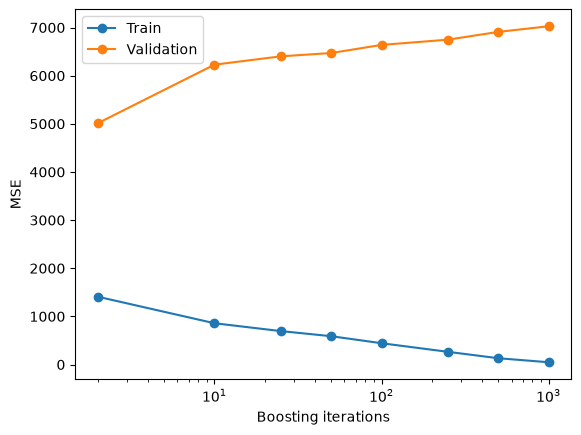

In [16]:
n_list = [2, 10, 25, 50, 100, 250, 500, 1000]
train_err, val_err = [], []

for n in n_list:
    m = xgb.XGBRegressor(n_estimators=n, random_state=42).fit(X_train, y_train)
    train_err.append(mean_squared_error(y_train, m.predict(X_train)))
    val_err.append(mean_squared_error(y_val, m.predict(X_val)))

plt.semilogx(n_list, train_err, 'o-', label='Train')
plt.semilogx(n_list, val_err, 'o-', label='Validation')
plt.xlabel('Boosting iterations'); plt.ylabel('MSE')
plt.legend()

5. Do you have evidence of overfitting to the training dataset with 1,000 boosting iterations?

**ANS Q5:** There is overfitting because th e training data and the validation split from each other and around 100 boosting iterations already does the job so there is overfitting when we increase the amount of iterations from there onwards.

6. Retrain the boosted regression tree using early stopping with a tolerance of 10. How many boosting iterations were optimal?

In [21]:
# early_stop_tol10 = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=10, random_state=42)
# early_stop_tol10.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
# print(early_stop_tol10.best_iteration)



In [20]:
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=42)

early_stop_tol10 = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=10, random_state=42)
early_stop_tol10.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print(early_stop_tol10.best_iteration)
# print(early_stop_tol10.best_score)


71


**ANS Q6:** 71 is optimal